In [1]:
# import libraries
import os
os.environ["OMP_NUM_THREADS"] = "2"
import urllib.request
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

In [2]:
# load dataset
dataset_url = "https://raw.githubusercontent.com/Graceagaba/Data_mining_assignment_2/main/wholesale-customers.csv"
file_name = "wholesale-customers.csv"

if not os.path.exists(file_name):
    print("Downloading dataset from GitHub...")
    urllib.request.urlretrieve(dataset_url, file_name)
    
df = pd.read_csv("wholesale-customers.csv")
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [3]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicatessen      440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB
None


data set has 440 rows and 8 columns, all columns are stored as integers,Channel and Region are category codes and the rest are annual spending .

In [4]:
# missing values
df.isnull().sum()

Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicatessen        0
dtype: int64

there are no missing values

In [5]:
# duplicates
df.duplicated().sum()

np.int64(0)

there are no duplicated variables

In [6]:
# statistics for the 6 spending variables
df.describe().round(0)

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
count,440.0,440.0,440.0,440.0,440.0,440.0,440.0,440.0
mean,1.0,3.0,12000.0,5796.0,7951.0,3072.0,2881.0,1525.0
std,0.0,1.0,12647.0,7380.0,9503.0,4855.0,4768.0,2820.0
min,1.0,1.0,3.0,55.0,3.0,25.0,3.0,3.0
25%,1.0,2.0,3128.0,1533.0,2153.0,742.0,257.0,408.0
50%,1.0,3.0,8504.0,3627.0,4756.0,1526.0,816.0,966.0
75%,2.0,3.0,16934.0,7190.0,10656.0,3554.0,3922.0,1820.0
max,2.0,3.0,112151.0,73498.0,92780.0,60869.0,40827.0,47943.0


# data preparation

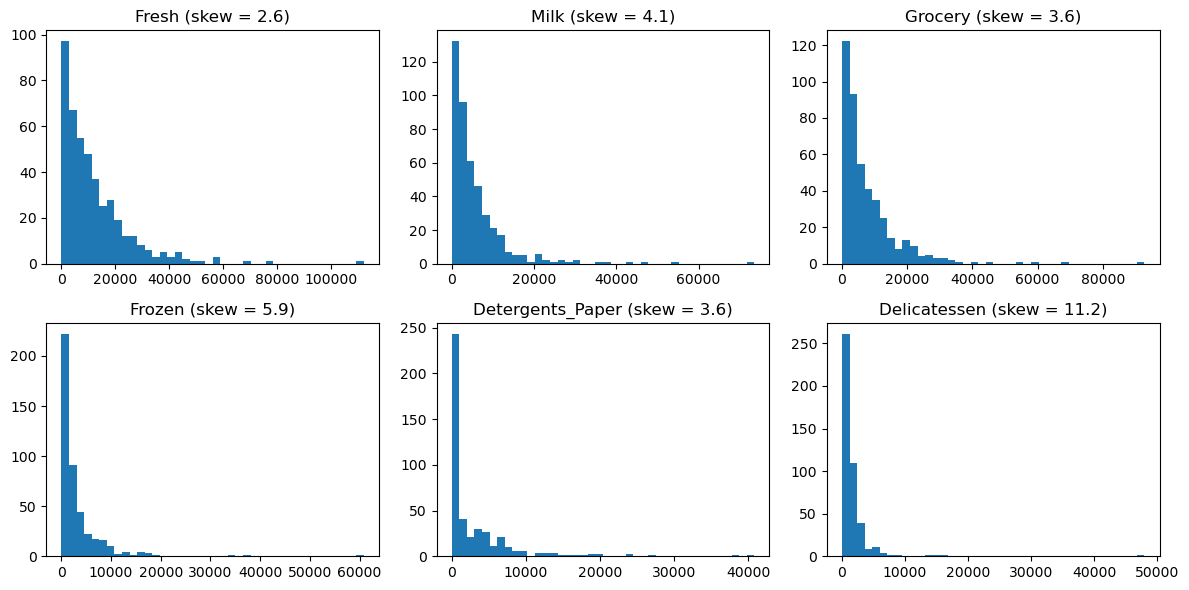

In [7]:
# check for skewness
spend_cols = ["Fresh","Milk","Grocery","Frozen","Detergents_Paper","Delicatessen"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.ravel(), spend_cols):
    ax.hist(df[col], bins=40)
    ax.set_title(f"{col} (skew = {df[col].skew():.1f})")
plt.tight_layout()
plt.show()

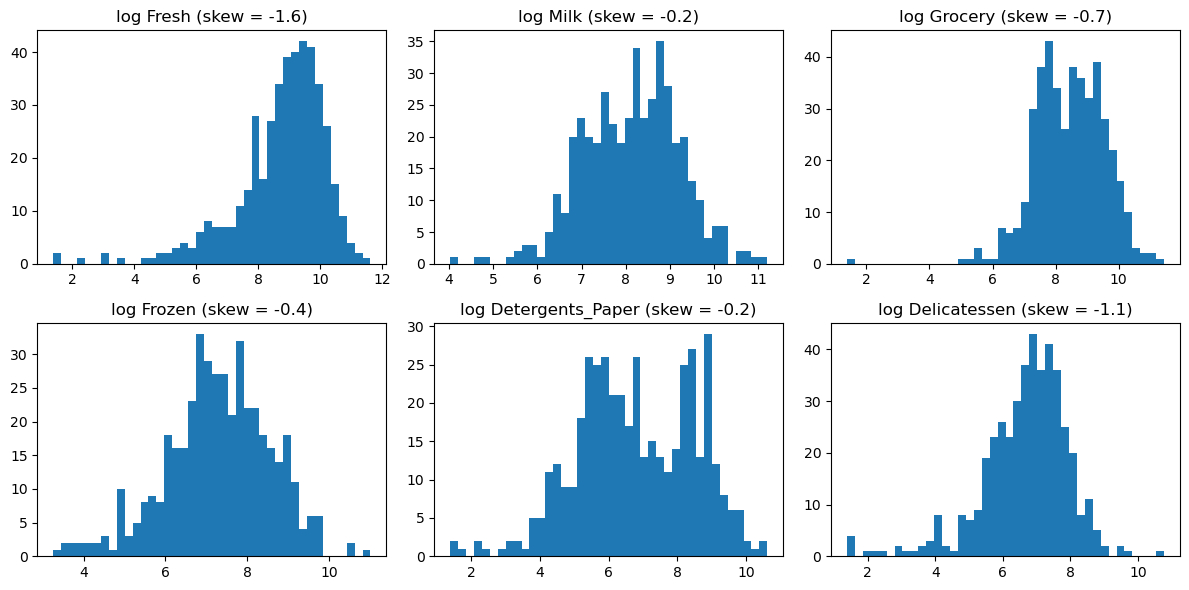

In [8]:
# log(1 + spending)
df_log = np.log1p(df[spend_cols])   

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.ravel(), spend_cols):
    ax.hist(df_log[col], bins=40)
    ax.set_title(f"log {col} (skew = {df_log[col].skew():.1f})")
plt.tight_layout()
plt.show()

In [9]:
# standardise the data
scaler = StandardScaler()
X = scaler.fit_transform(df_log) 

X_df = pd.DataFrame(X, columns=spend_cols)
print(X_df.mean().round(2))
print(X_df.std().round(2))

Fresh               0.0
Milk               -0.0
Grocery            -0.0
Frozen              0.0
Detergents_Paper   -0.0
Delicatessen       -0.0
dtype: float64
Fresh               1.0
Milk                1.0
Grocery             1.0
Frozen              1.0
Detergents_Paper    1.0
Delicatessen        1.0
dtype: float64


                  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicatessen
Fresh              1.00  0.10    -0.01    0.35             -0.10          0.24
Milk               0.10  1.00     0.73    0.12              0.66          0.41
Grocery           -0.01  0.73     1.00   -0.04              0.92          0.21
Frozen             0.35  0.12    -0.04    1.00             -0.13          0.39
Detergents_Paper  -0.10  0.66     0.92   -0.13              1.00          0.07
Delicatessen       0.24  0.41     0.21    0.39              0.07          1.00


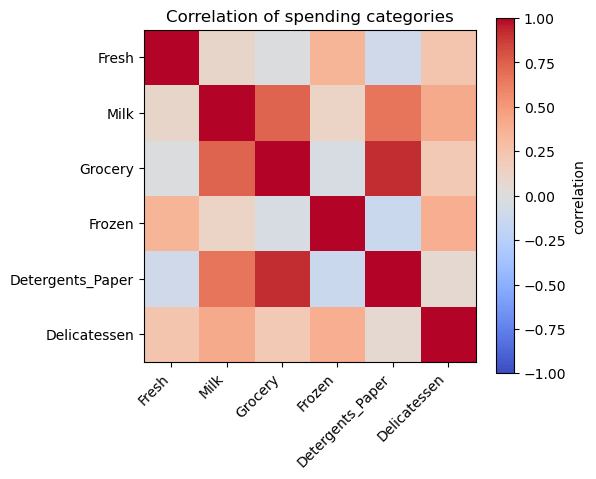

In [10]:
# correlations
corr = df[spend_cols].corr().round(2)
print(corr)

plt.figure(figsize=(6, 5))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="correlation")
plt.xticks(range(6), spend_cols, rotation=45, ha="right")
plt.yticks(range(6), spend_cols)
plt.title("Correlation of spending categories")
plt.tight_layout()
plt.show()

there is a very strong positive correlation between Detergents_Paper and Grocery(0.92), Grocery and milk(0.73) and Detergents_Paper and Milk(0.62) are also strongly correlated.Fresh and Frozen are largely independent of this group



# cluster tendencies

In [11]:
# checking clusters
def hopkins(data, m=44, seed=0):
    rng = np.random.default_rng(seed)
    n, d = data.shape
    nn = NearestNeighbors(n_neighbors=2).fit(data)

    # real customers -> distance to nearest OTHER real customer
    idx = rng.choice(n, m, replace=False)
    u = nn.kneighbors(data[idx], 2)[0][:, 1]

    # random points -> distance to nearest real customer
    random_pts = rng.uniform(data.min(axis=0), data.max(axis=0), (m, d))
    w = nn.kneighbors(random_pts, 1)[0][:, 0]

    return w.sum() / (w.sum() + u.sum())

scores = [hopkins(X, seed=s) for s in range(50)]
print("Hopkins on the prepared data:", round(np.mean(scores), 3))

# control: what does truly random data score?
rng = np.random.default_rng(1)
X_random = rng.uniform(X.min(axis=0), X.max(axis=0), X.shape)
print("Hopkins on random data:", round(np.mean([hopkins(X_random, seed=s) for s in range(50)]), 3))

Hopkins on the prepared data: 0.798
Hopkins on random data: 0.497


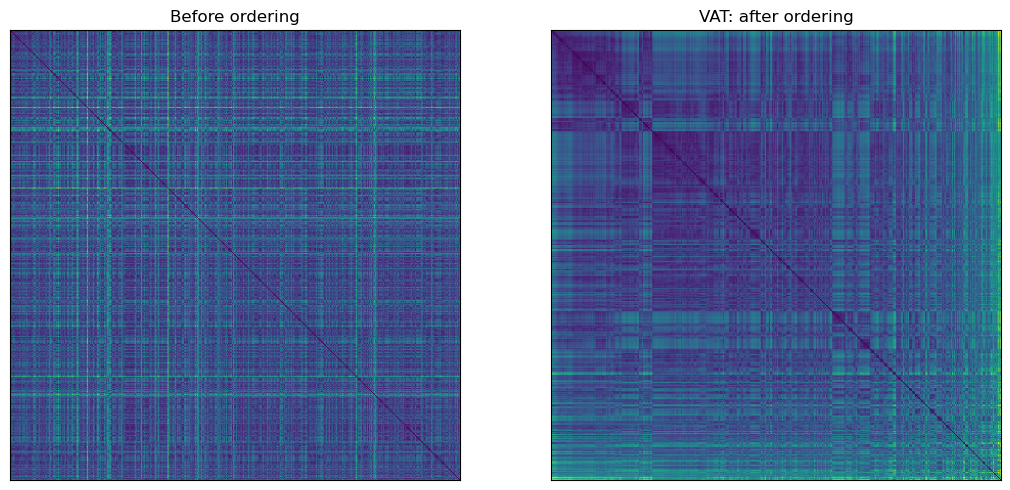

In [12]:
from scipy.spatial.distance import pdist, squareform

D = squareform(pdist(X))          

def vat_order(D):
    n = len(D)
    start = np.unravel_index(D.argmax(), D.shape)[0]   
    order = [start]
    remaining = set(range(n)) - {start}
    while remaining:
        rest = list(remaining)
        # next customer = the one closest to anyone already placed
        nearest = D[np.ix_(order, rest)].min(axis=0)
        nxt = rest[int(nearest.argmin())]
        order.append(nxt)
        remaining.remove(nxt)
    return np.array(order)

order = vat_order(D)

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(D, cmap="viridis")
ax[0].set_title("Before ordering")
ax[1].imshow(D[np.ix_(order, order)], cmap="viridis")
ax[1].set_title("VAT: after ordering")
for a in ax:
    a.set_xticks([])
    a.set_yticks([])
plt.tight_layout()
plt.show()

In [13]:
 # outlier check
Q1 = df[spend_cols].quantile(0.25)
Q3 = df[spend_cols].quantile(0.75)
IQR = Q3 - Q1
upper = Q3 + 1.5 * IQR

outlier_counts = (df[spend_cols] > upper).sum()
print(outlier_counts)
print("customers with at least one outlier:", (df[spend_cols] > upper).any(axis=1).sum())

Fresh               20
Milk                28
Grocery             24
Frozen              43
Detergents_Paper    30
Delicatessen        27
dtype: int64
customers with at least one outlier: 108


#  small report
The dataset has 440 customers and 8 variables .
There are no missing values ,no duplicate rows.
Fresh is te largest categpory with mean about 12,000, and Delicastessen the smallest(1,500)
Spending is strongly right skewed .the means are well above medians and skewness ranges from 2.6(Fresh) to 11.2((Delicatessen).
Between 20 and 43 values per category are flagged as outliers by the IQR rule and atleast 108 customers ave one outlier.
Grocery,Detergents_Paper and Milk are stringly correlated(0.92,0.73,0.66), meaning they are brougt as a bundle.
Fresh and Frozen are largely independent of that bundle.
    
Channel and Region excluded from clustering: they are labels, not spending, and the task is to segment by spending behaviour. They are used afterwards to validate the clusters.

Log transform, log(1 + x): reduces skew (for example Frozen from 5.9 to -0.4) so that a few very large customers do not dominate the distance calculations.

Standardisation: gives every category mean 0 and standard deviation 1, so no category counts more because of its units.

Outliers retained: they are genuine high-value customers, there are only 440 customers, and the log transform already limits their influence.
    
Hopkins statistic: about 0.80 on the prepared data, against about 0.50 for random data. A value above 0.75 indicates a clear tendency to cluster. (The raw-data value of 0.94 is inflated by skew and not relied on.)

VAT image: dark blocks along the diagonal show real structure, but the block edges are blurry. Customers form a continuum with several denser regions, so only moderate cluster quality should be expected.
Conclusion: the data are clusterable, with overlapping groups.

# Part 2 : Comparing partitioning, hierarchical and density-based clustering

In [14]:
# scoring helper
def score(X, labels):
    mask = labels != -1
    Xs, ls = X[mask], labels[mask]
    if len(set(ls)) < 2:
        return {"silhouette": np.nan, "davies_bouldin": np.nan, "calinski_harabasz": np.nan}
    return {"silhouette": silhouette_score(Xs, ls),
            "davies_bouldin": davies_bouldin_score(Xs, ls),
            "calinski_harabasz": calinski_harabasz_score(Xs, ls)}

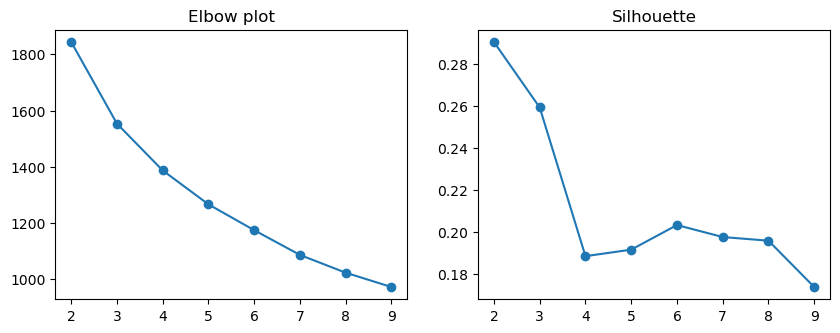

In [15]:
# k-means(partitioning)
ks = range(2, 10)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=25, random_state=0).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Elbow plot")
ax[1].plot(ks, sil, "o-");     ax[1].set_title("Silhouette")
plt.show()

The silhouette is higest at k=2 but that solution reproduces the oreca versus Retail split and the elbow plot has no sharp bend.I use k=4 because it separates two kinds of fresh oriented buyer and two kinds of packaged-goods buyer that k=2 and k=3 merge, which is more useful for the distributor.The cost is a lower silhouette about 0.19

In [16]:
# k-means,fit
km = KMeans(n_clusters=4, n_init=50, random_state=0).fit(X)
df["kmeans"] = km.labels_
kmeans_scores = score(X, km.labels_)
print(kmeans_scores)
print(df["kmeans"].value_counts().sort_index().to_dict())

{'silhouette': 0.1853077193422074, 'davies_bouldin': 1.550423457528868, 'calinski_harabasz': 131.35140284679858}
{0: 130, 1: 129, 2: 115, 3: 66}


# Hierarchical(ward)

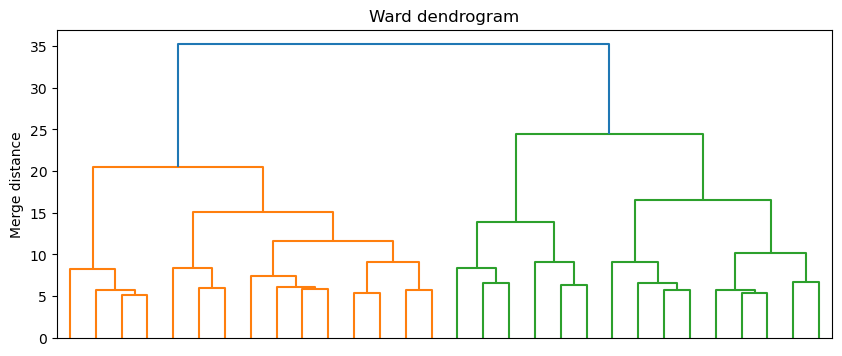

In [17]:
#hierarchical dendrogram
Z = linkage(X, method="ward")
plt.figure(figsize=(10, 4))
dendrogram(Z, truncate_mode="lastp", p=30, no_labels=True)
plt.title("Ward dendrogram"); plt.ylabel("Merge distance")
plt.show()

In [18]:
# hierarchical, fit Ward with k = 4
hier = AgglomerativeClustering(n_clusters=4, linkage="ward").fit(X)
df["ward"] = hier.labels_
ward_scores = score(X, hier.labels_)
print(ward_scores)
print(df["ward"].value_counts().sort_index().to_dict())

{'silhouette': 0.2020795686473931, 'davies_bouldin': 1.5210907132699092, 'calinski_harabasz': 108.60672962333317}
{0: 53, 1: 208, 2: 125, 3: 54}


In [19]:
# compare linkage types
rows = []
for link in ["ward", "complete", "average", "single"]:
    labels = AgglomerativeClustering(n_clusters=4, linkage=link).fit_predict(X)
    s = score(X, labels)
    s["linkage"] = link
    s["cluster sizes"] = np.bincount(labels).tolist()
    rows.append(s)
pd.DataFrame(rows).set_index("linkage").round(3)

,silhouette,davies_bouldin,calinski_harabasz,cluster sizes
linkage,,,,
ward,0.202,1.521,108.607,"[53, 208, 125, 54]"
complete,0.260,1.292,38.944,"[33, 391, 5, 11]"
average,0.498,0.330,8.383,"[437, 1, 1, 1]"
single,0.498,0.330,8.383,"[437, 1, 1, 1]"


single and average linkage reach a higher silhouette of about 0.50 only because they isolate one customer per cluster and leave 437 customers in a single cluster.These are useless for segmentationso a hig score must always be checked against the cluster sizes.ward gives a usable result although one cluster holds 208 customers wuch is about 47%

# DBSCAN(density-based)

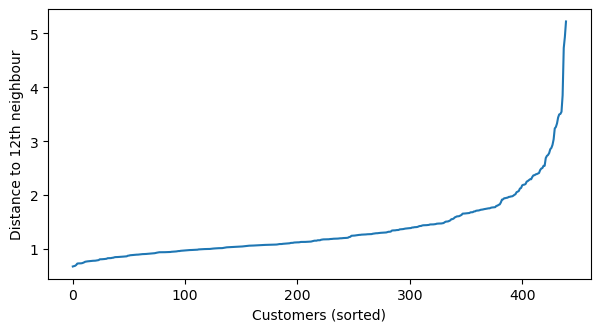

In [20]:
# DBSCAN, k-distance plot to help choose eps
min_samples = 12
dist = NearestNeighbors(n_neighbors=min_samples).fit(X).kneighbors(X)[0][:, -1]
plt.figure(figsize=(7, 3.5))
plt.plot(np.sort(dist))
plt.xlabel("Customers (sorted)"); plt.ylabel("Distance to 12th neighbour")
plt.show()

In [21]:
rows = []
for eps in [0.6, 0.8, 1.0, 1.2, 1.6]:
    for ms in [5, 12]:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        s = score(X, labels)["silhouette"]
        rows.append({"eps": eps, "min_samples": ms, "clusters": n_clusters,
                     "noise points": int((labels == -1).sum()),
                     "silhouette (non-noise)": None if np.isnan(s) else round(s, 3)})
pd.DataFrame(rows)

,eps,min_samples,clusters,noise points,silhouette (non-noise)
0,0.6,5,7,385,0.361
1,0.6,12,0,440,NaN
2,0.8,5,3,230,0.288
3,0.8,12,2,346,0.552
4,1.0,5,1,124,NaN
5,1.0,12,1,183,NaN
6,1.2,5,1,79,NaN
7,1.2,12,1,105,NaN
8,1.6,5,1,36,NaN
9,1.6,12,1,42,NaN


no setting gives several balanced clusters; small eps labels most customers as noise and larger eps merges almost everyone into one cluster.This fits the finding that the data form one continous cloud rather than separate islands

In [22]:
# DBSCAN, final model
db = DBSCAN(eps=0.8, min_samples=12).fit(X)
df["dbscan"] = db.labels_
dbscan_scores = score(X, db.labels_)
print("Clusters:", len(set(db.labels_)) - 1, " Noise:", int((db.labels_ == -1).sum()))
print(dbscan_scores)

Clusters: 2  Noise: 346
{'silhouette': 0.5517224250268672, 'davies_bouldin': 0.6902568143930314, 'calinski_harabasz': 178.2879299716254}


with esp=0.8 and min_samples = 12, DBSCAN finds 2 clusters(44 and 50 customers) and labels 346 of 440 customersas noise,thats about 79%.Its silhouette of 0.552 describes only tis dense core and ccanot be comaored directly with the other two methods

# side by side comparison

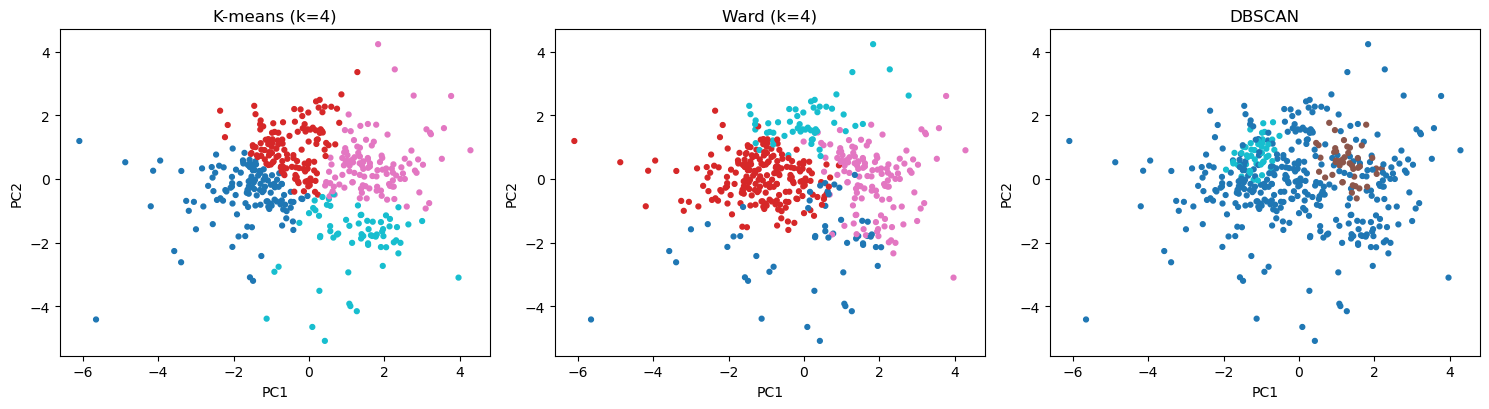

In [23]:
# plot all three methods side by side (PCA)
Y = PCA(n_components=2).fit_transform(X)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a, col, title in zip(ax, ["kmeans", "ward", "dbscan"],
                         ["K-means (k=4)", "Ward (k=4)", "DBSCAN"]):
    a.scatter(Y[:, 0], Y[:, 1], c=df[col], cmap="tab10", s=12)
    a.set_title(title); a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout(); plt.show()

In [24]:
# agreement between K-means and Ward
pd.crosstab(df["kmeans"], df["ward"], rownames=["K-means"], colnames=["Ward"])

Ward,0,1,2,3
K-means,,,,
0,12,118,0,0
1,1,76,5,47
2,6,7,95,7
3,34,7,25,0


In [25]:
# final comparison table
summary = pd.DataFrame({"K-means (k=4)": kmeans_scores,
                        "Ward (k=4)": ward_scores,
                        "DBSCAN": dbscan_scores}).T.round(3)
summary["clusters"] = [4, 4, len(set(db.labels_)) - 1]
summary["noise points"] = [0, 0, int((db.labels_ == -1).sum())]
summary

,silhouette,davies_bouldin,calinski_harabasz,clusters,noise points
K-means (k=4),0.185,1.550,131.351,4,0
Ward (k=4),0.202,1.521,108.607,4,0
DBSCAN,0.552,0.690,178.288,2,346


# small report
K-means is the best choice because it balances quality and interpretability, followed by Ward as useful cross-check and then DBSCAN.
Silhouette alone shouldnt decide beacuse the highest score came from degenerate solutions(single and average linkage, and DBSCAN's dense core) .Because the quality scores are modest overall (about 0.2), the segments should be seen as tendencies, not rigid boxes.  
    

# part 3 ; Cluster names and spending habits

In [26]:
# use the final K-means clusters from Part 2
df["cluster"] = df["kmeans"]
print(df["cluster"].value_counts().sort_index())

cluster
0    130
1    129
2    115
3     66
Name: count, dtype: int64


In [27]:


df = pd.read_csv("wholesale-customers.csv")
spend_cols = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicatessen"]

X = StandardScaler().fit_transform(np.log1p(df[spend_cols]))
km = KMeans(n_clusters=4, n_init=50, random_state=0).fit(X)
df["cluster"] = km.labels_

print(df["cluster"].value_counts().sort_index())


cluster
0    130
1    129
2    115
3     66
Name: count, dtype: int64


In [28]:
# profile each cluster in original units
# median spending per category
median = df.groupby("cluster")[spend_cols].median().round(0)
median["customers"] = df["cluster"].value_counts().sort_index()
median

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen,customers
cluster,,,,,,,
0,7814.0,1112.0,1820.0,1386.0,224.0,432.0,130
1,16933.0,3090.0,3417.0,4324.0,523.0,1365.0,129
2,8190.0,8579.0,12477.0,1455.0,4666.0,1776.0,115
3,1190.0,6672.0,10479.0,356.0,4218.0,303.0,66


In [29]:
# each cluster with overall average using a ratio table
overall = df[spend_cols].mean()
ratio = (df.groupby("cluster")[spend_cols].mean() / overall).round(2)
ratio

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
cluster,,,,,,
0,0.80,0.27,0.26,0.70,0.12,0.38
1,1.59,0.65,0.52,1.92,0.24,1.22
2,1.00,2.10,2.07,0.76,2.39,1.78
3,0.24,1.22,1.53,0.19,1.80,0.44


A ratio of 2.0 means twice the overall avearge , 0.5 means half and 1.0 is typical

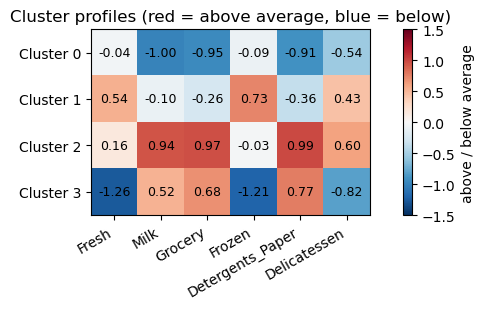

In [30]:
# using a heat map
z = pd.DataFrame(X, columns=spend_cols).groupby(df["cluster"]).mean()

fig, ax = plt.subplots(figsize=(7, 3.2))
im = ax.imshow(z.values, cmap="RdBu_r", vmin=-1.5, vmax=1.5)
ax.set_xticks(range(len(spend_cols))); ax.set_xticklabels(spend_cols, rotation=30, ha="right")
ax.set_yticks(range(4)); ax.set_yticklabels([f"Cluster {i}" for i in range(4)])
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        ax.text(j, i, f"{z.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, label="above / below average")
ax.set_title("Cluster profiles (red = above average, blue = below)")
plt.tight_layout(); plt.show()

Reading the heatmap (red = above average, blue = below average)

Cluster 0: near-average Fresh, well below average on Milk, Grocery, Detergents_Paper and Delicatessen.
Cluster 1: highest Fresh and Frozen, above-average Delicatessen, below average on Grocery and Detergents_Paper.
Cluster 2: highest Milk, Grocery, Detergents_Paper and Delicatessen (about 2 times the average), and average Fresh.
Cluster 3: high Grocery, Milk and Detergents_Paper, very low Fresh and Frozen.

# checking for unclustered variables(Channel and Region)

In [31]:

# channel(1 = Horeca ie hotels,restaurants and cafes ; 2 = Retail) and Region # Horeca vs Retail per cluster
channel = pd.crosstab(df["cluster"], df["Channel"])
channel.columns = ["Horeca (1)", "Retail (2)"]
channel["% Retail"] = (channel["Retail (2)"] / channel.sum(axis=1) * 100).round(0)
channel


,Horeca (1),Retail (2),% Retail
cluster,,,
0,129,1,1.0
1,122,7,5.0
2,22,93,81.0
3,25,41,62.0


In [32]:
region = pd.crosstab(df["cluster"], df["Region"], normalize="index").round(2) * 100
region.columns = ["Region 1 %", "Region 2 %", "Region 3 %"]
region

,Region 1 %,Region 2 %,Region 3 %
cluster,,,
0,20.0,8.0,72.0
1,17.0,13.0,70.0
2,17.0,10.0,73.0
3,15.0,11.0,74.0


Channel helps with the naming: clusters 0 and 1 are almost entirely Horeca (99% and 95%), cluster 2 is mostly Retail (81%), and cluster 3 is mixed (62% Retail).
Region 3 holds about 70 to 74% of every cluster, the same as in the whole dataset, so Region does not separate the clusters and is not used in the names.

# cluster that matters most

In [33]:
# share of customers vs sare of total spend
df["total_spend"] = df[spend_cols].sum(axis=1)

business = pd.DataFrame({
    "customers": df["cluster"].value_counts().sort_index(),
    "% of customers": (df["cluster"].value_counts(normalize=True).sort_index() * 100).round(1),
    "mean total spend": df.groupby("cluster")["total_spend"].mean().round(0),
    "% of all spend": (df.groupby("cluster")["total_spend"].sum() / df["total_spend"].sum() * 100).round(1),
})
business

,customers,% of customers,mean total spend,% of all spend
cluster,,,,
0,130,29.5,16324.0,14.5
1,129,29.3,35487.0,31.3
2,115,26.1,52525.0,41.3
3,66,15.0,28472.0,12.9


Cluster 2 is the most valuable segment: it has only 26.1% of customers but 41.3% of all spend (mean total spend about 52,500). Clusters 1 and 2 together are about 55% of customers but about 73% of all spend. Cluster 3 is the smallest segment and contributes only 12.9% of spend.

# cluster names

In [34]:
names = {
    0: "Small Fresh-Food Buyers",
    1: "Large Fresh and Frozen Buyers",
    2: "Big Retail All-Category Buyers",
    3: "Grocery and Household Specialists",
}
df["segment"] = df["cluster"].map(names)

summary = df.groupby("segment")[spend_cols].mean().round(0).astype(int)
summary["customers"] = df["segment"].value_counts()
summary["% Retail"] = df.groupby("segment")["Channel"].apply(lambda s: round((s == 2).mean() * 100))
summary["% of all spend"] = (df.groupby("segment")["total_spend"].sum() / df["total_spend"].sum() * 100).round(1)
summary.sort_values("% of all spend", ascending=False)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen,customers,% Retail,% of all spend
segment,,,,,,,,,
Big Retail All-Category Buyers,11969,12160,16451,2350,6879,2718,115,81,41.3
Large Fresh and Frozen Buyers,19101,3775,4152,5910,692,1856,129,5,31.3
Small Fresh-Food Buyers,9628,1536,2077,2158,347,577,130,1,14.5
Grocery and Household Specialists,2850,7049,12138,582,5187,666,66,62,12.9


# Descriptions and spending habits

Cluster 0: Small Fresh-Food Buyers (130 customers, 99% Horeca).** They spend a moderate amount on Fresh (about 9,600) and Frozen (about 2,200) and very little on everything else. They are probably small cafes and eateries that buy mainly perishable food from this distributor. They have the lowest spend per customer (about 16,300) and 14.5% of total spend.
    
Cluster 1: Large Fresh and Frozen Buyers (129 customers, 95% Horeca).** They spend the most on Fresh (about 19,100) and Frozen (about 5,900), with above-average Delicatessen, but little on Grocery and Detergents_Paper. They are probably restaurants, hotels and caterers whose business depends on volumes of perishable food. They have 31.3% of total spend.

Cluster 2: Big Retail All-Category Buyers (115 customers, 81% Retail).** They spend the most on Milk (about 12,200), Grocery (about 16,500), Detergents_Paper (about 6,900) and Delicatessen (about 2,700), and also a lot on Fresh (about 12,000). They are probably supermarkets and large shops stocking a full range. They are 26% of customers but 41.3% of total spend.

Cluster 3: Grocery and Household Specialists (66 customers, 62% Retail).** They spend a lot on Grocery (about 12,100), Milk (about 7,000) and Detergents_Paper (about 5,200) but almost nothing on Fresh (about 2,900) or Frozen (about 600). They are probably convenience stores and small shops selling packaged goods. They are the smallest segment, with 12.9% of total spend.

Overall spending habits
Customers fall into two families: perishables (clusters 0 and 1) and packaged goods (clusters 2 and 3). Within each family, customers differ mainly in scale.
Grocery, Milk and Detergents_Paper are bought together, while Fresh and Frozen are bought separately from them.
Revenue is concentrated: clusters 1 and 2 are about 55% of customers but about 73% of spend.
Channel explains part of the structure but not all of it, because cluster 3 is mixed. Region does not matter.
Many customers buy only part of the range from the distributor (cluster 0 buys almost no packaged goods and cluster 3 almost no fresh food), so there is room to sell them more.

The clusters overlap (silhouette about 0.19), so customers near a boundary could belong to a neighbouring group. The names are inferred from spending and channel, not from knowing what each business does. The data are annual totals only, so seasonality and profit cannot be assessed

In [35]:
# summary table
names = {
    0: "Small Fresh-Food Buyers",
    1: "Large Fresh and Frozen Buyers",
    2: "Big Retail All-Category Buyers",
    3: "Grocery and Household Specialists",
}
df["segment"] = df["cluster"].map(names)

summary = df.groupby("segment")[spend_cols].mean().round(0).astype(int)
summary["customers"] = df["segment"].value_counts()
summary["% Retail"] = df.groupby("segment")["Channel"].apply(lambda s: round((s == 2).mean() * 100))
summary["% of all spend"] = (df.groupby("segment")["total_spend"].sum() / df["total_spend"].sum() * 100).round(1)
summary.sort_values("% of all spend", ascending=False)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen,customers,% Retail,% of all spend
segment,,,,,,,,,
Big Retail All-Category Buyers,11969,12160,16451,2350,6879,2718,115,81,41.3
Large Fresh and Frozen Buyers,19101,3775,4152,5910,692,1856,129,5,31.3
Small Fresh-Food Buyers,9628,1536,2077,2158,347,577,130,1,14.5
Grocery and Household Specialists,2850,7049,12138,582,5187,666,66,62,12.9


# Cluster names and spending habits
Cluster 0, Small Fresh-Food Buyers: moderate Fresh (about 9,600), very little of everything else; 99% Horeca, so probably small cafes and eateries. Lowest spend per customer (about 16,300).

Cluster 1, Large Fresh and Frozen Buyers: highest Fresh (about 19,100) and Frozen (about 5,900), low Grocery and Detergents; 95% Horeca, so probably restaurants, hotels and caterers. 31.3% of total spend.

Cluster 2, Big Retail All-Category Buyers: highest Milk, Grocery, Detergents and Delicatessen, plus high Fresh; 81% Retail, so probably supermarkets and large shops. 26% of customers but 41.3% of total spend, the most valuable segment.

Cluster 3, Grocery and Household Specialists: high Grocery, Milk and Detergents but almost no Fresh or Frozen; mixed channel (62% Retail). The smallest segment, 12.9% of spend.

Overall: customers split into a perishables family (clusters 0 and 1) and a packaged-goods family (clusters 2 and 3). Grocery, Milk and Detergents are bought together. Clusters 1 and 2 are 55% of customers but about 73% of spend. Region does not separate the clusters. Many customers buy only part of the range, so there is room to sell them more. Limitation: the clusters overlap (silhouette about 0.19) and the names are inferred from spending and channel, not known facts.